# Panel 4 and 5

This notebook contains the majority of the images for the fourth and fifth panels of the paper, including the likelihood scans, and GP parameter fits. Data is imported from the fitted GPs, and from the saved likelihood scans.

In [1]:
# Autoreloading of modules and files without restarting notebook.
%reload_ext autoreload
%autoreload 2

import os
import numpy as np
import pandas as pd
from pathlib import Path
from copy import deepcopy
from math import log10, floor
import matplotlib.pyplot as plt

from rvm_analysis.colours import get_cell_colour, generate_color_spectrum
from rvm_analysis.save_tools import save_in_folder
from rvm_analysis.plotting import plot_rainclouds

#! Force the backend back to matplotlib inline (after importing viziphant).
%matplotlib inline
print(plt.get_backend())

C:\Users\carla\AppData\Local\Temp\ipykernel_7528\7070265.py:7: DeprecationWarning: 
Pyarrow will become a required dependency of pandas in the next major release of pandas (pandas 3.0),
(to allow more performant data types, such as the Arrow string type, and better interoperability with other libraries)
but was not found to be installed on your system.
If this would cause problems for you,
please provide us feedback at https://github.com/pandas-dev/pandas/issues/54466
        
  import pandas as pd


module://matplotlib_inline.backend_inline


These paths are required to have the GP fit and likelihood scan output results in order to run.

In [ ]:
gaussian_process_param_save_directory = Path("./results/gen_pois_trunc/")
image_save_path: Path = Path("./Images")
hyperparameter_dataframe_name = "combined_data.csv"

## Combine the two neutral datasets for plotting

In [3]:
fontsize = 7
plt.rcParams['savefig.pad_inches'] = 0
plt.rcParams["xtick.labelsize"] = fontsize
plt.rcParams["ytick.labelsize"] = fontsize

# Plot period scopes

## Plotting GP parameter fits

            model_id cell_name  id  lengthscale  period_length  outputscale  \
0               ON_0        ON   0     0.726960     298.866897     3.612001   
1               ON_1        ON   1     0.742050     297.557261     5.699948   
2               ON_2        ON   2     0.705516     298.100009    32.188076   
3               ON_3        ON   3     0.743217     301.245178     0.386149   
4               ON_4        ON   4     0.689997     296.297928     5.231079   
..               ...       ...  ..          ...            ...          ...   
77   NEUTRAL_EXTRA_7   NEUTRAL   7     0.758397     299.324271     0.017759   
78   NEUTRAL_EXTRA_8   NEUTRAL   8     0.743374     297.043875     0.052846   
79   NEUTRAL_EXTRA_9   NEUTRAL   9     0.751136     300.535139     0.048061   
80  NEUTRAL_EXTRA_10   NEUTRAL  10     0.735607     295.802001     0.085285   
81  NEUTRAL_EXTRA_11   NEUTRAL  11     0.758385     302.144634     0.010746   

           w  noise_prob  Train Model ELPD  Train M

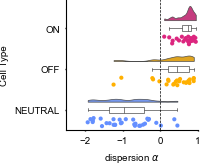

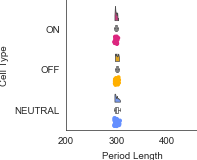

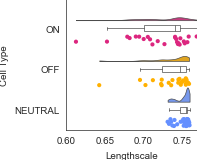

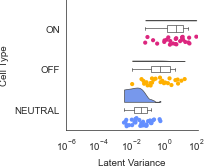

c:\Users\carla\Documents\Cambridge\PhD\Paper_1\Submission\Publication_Code\Multi-timescale-Rhythmic-Dynamics-in-RVM-neurons\env\lib\site-packages\seaborn\categorical.py:253: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  grouped_vals = vals.groupby(grouper)
c:\Users\carla\Documents\Cambridge\PhD\Paper_1\Submission\Publication_Code\Multi-timescale-Rhythmic-Dynamics-in-RVM-neurons\env\lib\site-packages\seaborn\categorical.py:253: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  grouped_vals = vals.groupby(grouper)
c:\Users\carla\Documents\Cambridge\PhD\Paper_1\Submission\Publication_Code\Multi-timescale-Rhythmic-Dy

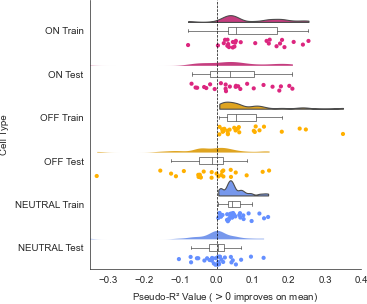

In [4]:
custom_palette={
    "ON Train": get_cell_colour(names="ON"),
    "ON Test": get_cell_colour(names="ON"),
    "OFF Train": get_cell_colour(names="OFF"),
    "OFF Test": get_cell_colour(names="OFF"),
    "NEUTRAL Train": get_cell_colour(names="NEUTRAL"),
    "NEUTRAL Test": get_cell_colour(names="NEUTRAL"),
}
custom_palette_w={
    "ON": get_cell_colour(names="ON"),
    "OFF": get_cell_colour(names="OFF"),
    "NEUTRAL": get_cell_colour(names="NEUTRAL"),
}

def plot_kernel_results_from_path(data_path: Path,kernel_name: str, dataframe_name: str, save_path: Path):
    """
    Plots the parameter fits of the Poisson GP kernel,
    taking a path to the directory where the saved parameters are located,
    and the name of the kernel (model shorthand) for saving only.
    """
    with open(os.path.join(data_path,dataframe_name)) as data_csv:
        df = pd.read_csv(data_csv)
        print(df)

        size = 1.7
        fig, ax = plt.subplots(figsize=(size,size))
        plot_rainclouds(data_csv,'w',df,xlim=[-2.5,1.0],move=0.3,
                        custom_palette=custom_palette_w, ax=ax, xlabel="dispersion $\\alpha$")
        save_in_folder(f"{kernel_name}_w",basePath="./Images",svg=True,save=True)


        fig, ax = plt.subplots(figsize=(size,size))
        plot_rainclouds(data_csv,'period_length',df,xlim=[200,460.0],move=0.3,
                        custom_palette=custom_palette_w, ax=ax, xlabel="Period Length")
        save_in_folder(f"{kernel_name}_period_length",basePath="./Images",svg=True,save=True)

        fig, ax = plt.subplots(figsize=(size,size))
        plot_rainclouds(data_csv,'lengthscale',df,xlim=[0.6,0.77],move=0.3,
                        custom_palette=custom_palette_w, ax=ax, xlabel="Lengthscale")
        save_in_folder(f"{kernel_name}_lengthscale",basePath="./Images",svg=True,save=True)

        fig, ax = plt.subplots(figsize=(size,size))
        plot_rainclouds(data_csv,'outputscale',df,xlim=[1e-6,120.0],move=0.3,
                        custom_palette=custom_palette_w, ax=ax, xlabel="Latent Variance")
        ax.set_xscale("log")
        save_in_folder(f"{kernel_name}_outputscale",basePath="./Images",svg=True,save=True)


    # Load the data
    df = pd.read_csv(os.path.join(data_path, "combined_data.csv"))

    train: pd.DataFrame = df[['cell_name', 'Train Pseudo-R2']].copy() #type: ignore
    train['cell_name'] = train['cell_name'] + ' Train'
    train = train.rename(columns={'Train Pseudo-R2': 'Pseudo-R2'}) #type: ignore

    test: pd.DataFrame = df[['cell_name', 'Test Pseudo-R2']].copy() #type: ignore
    test['cell_name'] = test['cell_name'] + ' Test'
    test = test.rename(columns={'Test Pseudo-R2': 'Pseudo-R2'})# type: ignore


    # Combine into one long-format DataFrame
    df_combined: pd.DataFrame = pd.concat([test, train], ignore_index=True)
    df_combined['cell_name'] = pd.Categorical(df_combined['cell_name'],categories=custom_palette.keys(),ordered=False)
    df_sorted=df_combined
    df_sorted = df_combined.sort_values('cell_name')
    # print(df_sorted)
    # Plot
    f, ax = plt.subplots(figsize=(3.5, 3.5))
    plot_rainclouds(None, 'Pseudo-R2', df_sorted, xlim=[-0.35, 0.4], ax=ax,
                    custom_palette=custom_palette,move=0.3,cloud_linewidths = [0.8,0.0,0.8,0.0,0.8,0.0]
    )

    # laeset_position((-0.2,0.5))
    # plt.tight_layout(h_pad=0.6)
    save_in_folder(f"{kernel_name}_r2_plot",save_path,svg=True,save=True)

plot_kernel_results_from_path(kernel_name="periodic",
                              data_path = gaussian_process_param_save_directory, dataframe_name=hyperparameter_dataframe_name,save_path=image_save_path)


## Printing GP hyperparameter value statistics

In [5]:
def get_param(param_name,data_path: Path,dataframe_name: str):
        """ Gets the mean, standard deviation, and count of a parameter. """
        with open(data_path / dataframe_name) as data_csv:
                df = pd.read_csv(data_csv)

                print(df.groupby('cell_name')[param_name].mean())
                print(df.groupby('cell_name')[param_name].std())
                print(df.groupby('cell_name')[param_name].count())

In [6]:
get_param("lengthscale",
        data_path= gaussian_process_param_save_directory, dataframe_name = hyperparameter_dataframe_name
        )

get_param("period_length",
        data_path= gaussian_process_param_save_directory, dataframe_name = hyperparameter_dataframe_name
        )

# This is alpha
get_param("w",
        data_path= gaussian_process_param_save_directory, dataframe_name = hyperparameter_dataframe_name
        )

get_param("outputscale",
        data_path= gaussian_process_param_save_directory, dataframe_name = hyperparameter_dataframe_name
        )

cell_name
NEUTRAL    0.750745
OFF        0.736342
ON         0.720809
Name: lengthscale, dtype: float64
cell_name
NEUTRAL    0.008835
OFF        0.026376
ON         0.037291
Name: lengthscale, dtype: float64
cell_name
NEUTRAL    32
OFF        25
ON         25
Name: lengthscale, dtype: int64
cell_name
NEUTRAL    299.366857
OFF        300.184675
ON         298.272250
Name: period_length, dtype: float64
cell_name
NEUTRAL    3.285293
OFF        2.622770
ON         1.992490
Name: period_length, dtype: float64
cell_name
NEUTRAL    32
OFF        25
ON         25
Name: period_length, dtype: int64
cell_name
NEUTRAL   -0.900765
OFF        0.350181
ON         0.672543
Name: w, dtype: float64
cell_name
NEUTRAL    0.647103
OFF        0.548181
ON         0.227815
Name: w, dtype: float64
cell_name
NEUTRAL    32
OFF        25
ON         25
Name: w, dtype: int64
cell_name
NEUTRAL     0.092793
OFF         2.503448
ON         12.987113
Name: outputscale, dtype: float64
cell_name
NEUTRAL     0.142449
OFF 

In [7]:
params = ["period_length", "w", "outputscale","lengthscale", ]

def format_sigfig_no_sci(x, sig=2):
    """
    Formats a number to `sig` significant figures without scientific notation.
    """
    if pd.isna(x):
        return ""

    if x == 0:
        return "0"

    # number of digits before decimal
    power = floor(log10(abs(x)))

    # digits after decimal
    decimals = sig - power - 1
    decimals = max(decimals, 0)
    fmt = "{:." + str(decimals) + "f}"
    out = fmt.format(x)

    out = out.rstrip("0").rstrip(".")
    return out

def make_latex_table(base_save_dir: Path, dataframe_name: str, output_tex_path="param_table.tex"):
    """
    Makes a latex table with the output parameter values in it.
    """
    df = pd.read_csv(os.path.join(base_save_dir, dataframe_name))

    rows = []
    cell_names = df['cell_name'].unique()

    for cell in cell_names:
        row = [cell]
        cell_df = df[df['cell_name'] == cell]

        for p in params:
            mean_val = cell_df[p].mean()
            std_val  = cell_df[p].std()

            mean_f = format_sigfig_no_sci(mean_val, 2)
            std_f  = format_sigfig_no_sci(std_val, 2)

            row.append(f"{mean_f} \\pm {std_f}")

        rows.append(row)

    # Build the table
    header = "Cell & " + " & ".join(params) + " \\\\"
    latex = [
        "\\begin{table}[h!]",
        "\\centering",
        "\\begin{tabular}{l" + "c" * len(params) + "}",
        "\\hline",
        header,
        "\\hline"
    ]

    for r in rows:
        latex.append(" & ".join(r) + " \\\\")

    latex += [
        "\\hline",
        "\\end{tabular}",
        "\\caption{Parameter means $\\pm$ std (2 significant figures, no scientific notation).}",
        "\\end{table}"
    ]

    latex_text = "\n".join(latex)

    with open(output_tex_path, "w") as f:
        f.write(latex_text)

    print(f"LaTeX table written to {output_tex_path}")


make_latex_table(base_save_dir= gaussian_process_param_save_directory, dataframe_name = hyperparameter_dataframe_name
)


LaTeX table written to param_table.tex
